# Grouding inference

In [ ]:
import torch
from PIL import Image, ImageDraw
from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor

/home/rafal/Repositories/GroundingDINO_reproduction/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# 1. Wybór urządzenia
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Używam urządzenia: {device}")

Używam urządzenia: cuda


In [3]:
# 2. Załadowanie procesora i modelu (model tiny pobierze się automatycznie, ~680 MB)
model_id = "IDEA-Research/grounding-dino-tiny"
processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForZeroShotObjectDetection.from_pretrained(model_id).to(device)

Loading weights: 100%|██████████| 978/978 [00:00<00:00, 4204.41it/s]


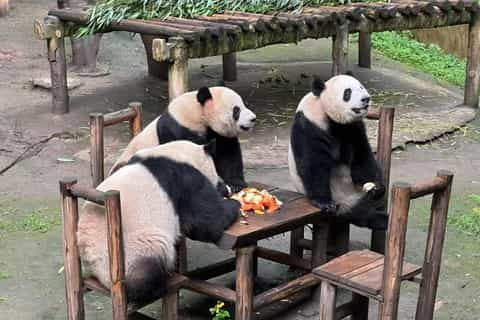

In [26]:
# 3. Przykładowe dane: jedno zdjęcie z sieci
image = Image.open('/home/rafal/Repositories/GroundingDINO_reproduction/src/data/panda.jpg')
image.show()

Wykryto: 'a chair' z pewnością 0.39 na pozycji [310.82, 168.68, 454.79, 318.4]
Wykryto: 'a panda' z pewnością 0.46 na pozycji [286.14, 69.97, 388.67, 220.03]
Wykryto: 'a panda' z pewnością 0.27 na pozycji [108.48, 81.98, 258.81, 192.14]
Wykryto: 'a panda' z pewnością 0.26 na pozycji [84.54, 138.05, 240.95, 298.06]


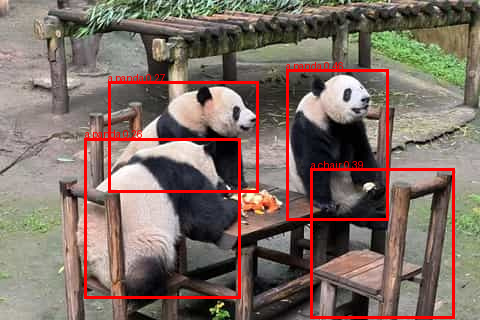


Zapisano obraz z detekcjami jako 'wynik.jpg'.


In [27]:
# 4. Prompt tekstowy – klasy MUSZĄ być zakończone kropką!
text_prompt = "a panda . a chair ."

# 5. Przygotowanie tensorów
inputs = processor(images=image, text=text_prompt, return_tensors="pt").to(device)

# 6. Predykcja
with torch.no_grad():
    outputs = model(**inputs)

# 7. Konwersja wyników do pikseli
target_sizes = [image.size[::-1]]  # (height, width)
results = processor.post_process_grounded_object_detection(
    outputs,
    inputs.input_ids,
    threshold=0.25,
    text_threshold=0.25,
    target_sizes=target_sizes
)[0]

# 8. Rysowanie i zapis wyniku
draw = ImageDraw.Draw(image)
for score, label, box in zip(results["scores"], results["labels"], results["boxes"]):
    box = [round(i, 2) for i in box.tolist()]
    print(f"Wykryto: '{label}' z pewnością {score:.2f} na pozycji {box}")
    draw.rectangle(box, outline="red", width=3)
    draw.text((box[0], box[1] - 10), f"{label} {score:.2f}", fill="red")

image.save("results/wynik.jpg")
image.show()
print("\nZapisano obraz z detekcjami jako 'wynik.jpg'.")